# Track a moving Blob
Colour-based tracking of a single object. Instead of naming a colour, you outline the object in a few frames and the notebook learns its colour from the pixels inside those outlines. The example tracks the yellow water polo ball in the trimmed video, restricted to when it is in the air.

To track something else: set the video in **Step 0**, pick frames where the object is visible in **Step 2**, outline it in **Step 3**, and run the rest. Steps 10–11 assume a round object of known size in free flight (a thrown ball); skip them for other objects.

## Step 0: Settings
The video to track, a short label used in the output file names, and how many evenly spaced frames to preview in Step 1.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.ticker import MultipleLocator
from pathlib import Path

VIDEO = Path("/Users/souvikmandal/Documents/S06_Teaching_Mentoring_Talks/LS100/2026_Sem2/data/raw/water-polo_maya/01-F-01-TL-Back-2_trimmed.mp4")
LABEL = "ball"   # used in the output file names: <video>_<LABEL>_track.csv and <video>_<LABEL>_tracked.mp4
N_PREVIEW = 12   # number of evenly spaced frames shown in Step 1 to choose sample frames from

## Step 1: Load the video
Reads all frames of the video into memory and shows `N_PREVIEW` evenly spaced frames. Note the numbers of frames where the object is clearly visible.

222 frames, 1420x400, 59.94 fps


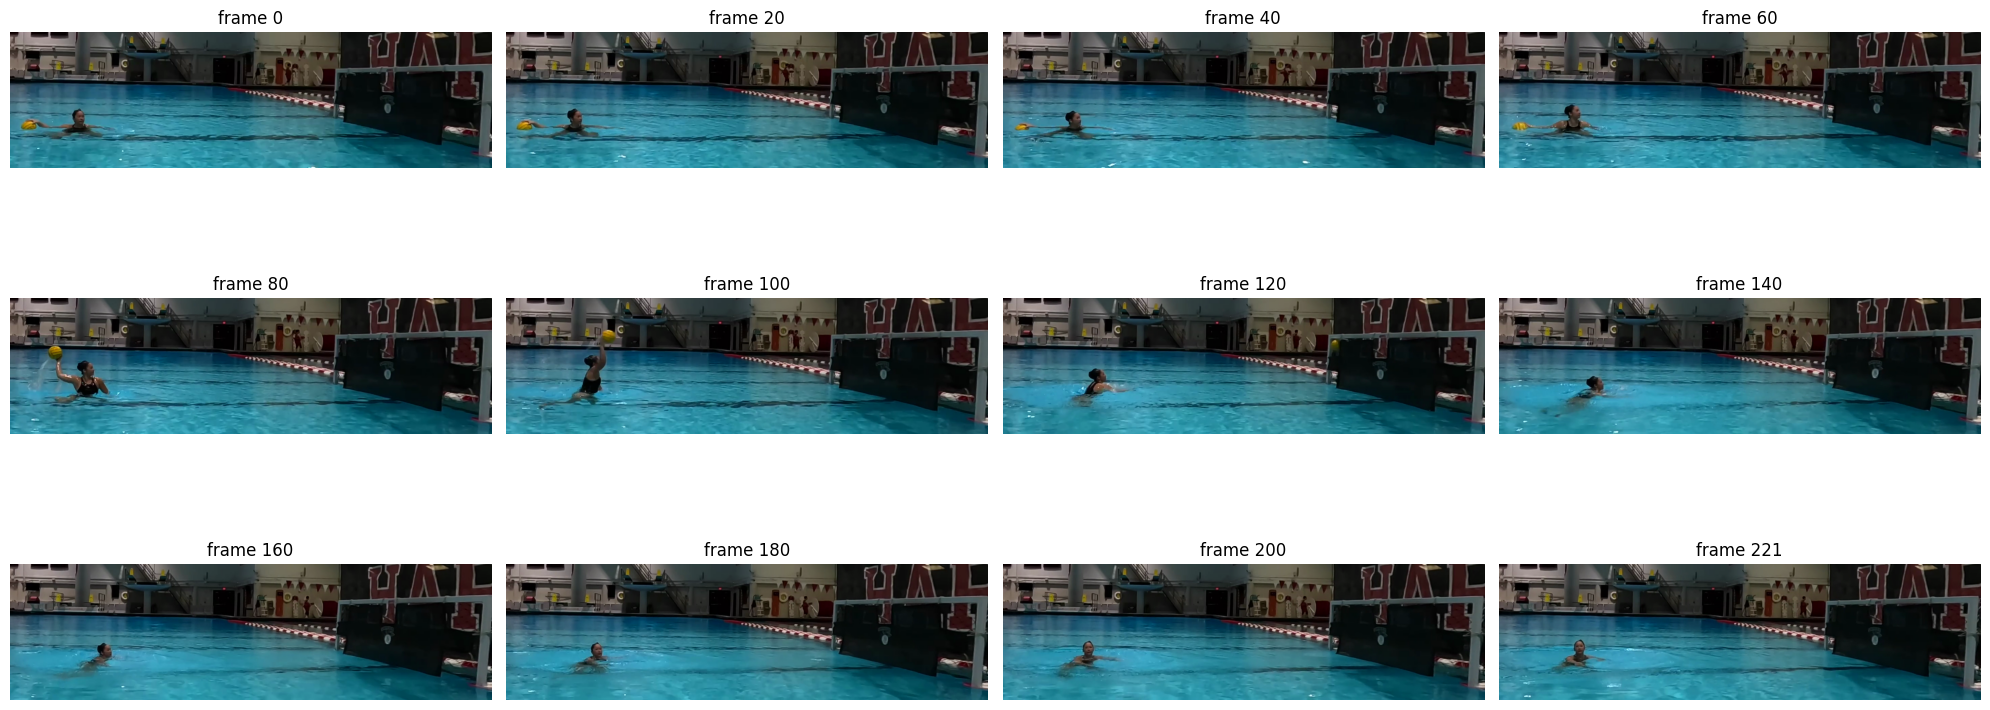

In [24]:
cap = cv2.VideoCapture(str(VIDEO))
frames = []
while True:
    ok, f = cap.read()
    if not ok:
        break
    frames.append(f)
fps = cap.get(cv2.CAP_PROP_FPS)
cap.release()
H, W = frames[0].shape[:2]
print(f"{len(frames)} frames, {W}x{H}, {fps:.2f} fps")

idx = np.linspace(0, len(frames) - 1, N_PREVIEW).astype(int)
rows = -(-N_PREVIEW // 4)
fig, axes = plt.subplots(rows, 4, figsize=(20, 3 * rows), squeeze=False)
for ax in axes.ravel()[N_PREVIEW:]:
    ax.axis("off")
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB)); ax.set_title(f"frame {i}"); ax.axis("off")
plt.tight_layout(); plt.show()

## Step 2: Pick sample frames
From the preview above, list 1–4 frames where the object is clearly visible in `SAMPLE_FRAMES`. Choose frames in different conditions (e.g. on the water and in flight, near and far, light and shade) so the learned colour covers all of them. If the track is later lost in some frames (Step 6), add one of those frames here and outline it too. Each frame is shown large with a grid in pixel coordinates (x to the right, y downwards) to read off where the object is.

> **Why type coordinates?** A simple click-to-outline interface (e.g. OpenCV's `cv2.selectROI` window) would be quicker, but it opens a window on the screen of the computer running Python. In a notebook running on Colab or any other remote Jupyter server that computer has no screen, so the window cannot appear. Typed coordinates work everywhere.

In [ ]:
SAMPLE_FRAMES = [20, 50, 80, 100]   # frames where the object is clearly visible
# (50 is not in the preview: it was added because the track was first lost in frames 46-56, where the ball is pushed under water)

def show_grid(ax, img, x0=0, y0=0):
    """Show a BGR image (or a crop whose top-left corner is at x0, y0) with axes and a grid in frame pixel coordinates."""
    h, w = img.shape[:2]
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), extent=(x0 - 0.5, x0 + w - 0.5, y0 + h - 0.5, y0 - 0.5))
    step = next(s for s in (1, 2, 5, 10, 20, 25, 50, 100, 200, 250, 500, 1000) if s >= max(w, h) / 15)
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(MultipleLocator(step))
        axis.set_minor_locator(MultipleLocator(step / 5))
    ax.grid(which="major", color="w", lw=0.8, alpha=0.7)
    ax.grid(which="minor", color="w", lw=0.3, alpha=0.4)
    ax.tick_params(labelsize=8)

for i in SAMPLE_FRAMES:
    fig, ax = plt.subplots(figsize=(20, 20 * H / W + 0.6))
    show_grid(ax, frames[i]); ax.set_title(f"frame {i}")
    plt.tight_layout(); plt.show()

## Step 3: Outline the object
For each sample frame, enter 3 to 6 `(x, y)` points that go around the object in order (clockwise or anticlockwise) in `OUTLINES`. Place the points **just inside** the object's edge: any background inside the polygon would be learned as object colour. The plot zooms in on each outline with a finer grid; adjust the points and rerun until the red polygon covers only the object.

In [ ]:
OUTLINES = {   # frame: [(x, y), ...] with 3 to 6 points
    20:  [(40, 280), (46, 270), (62, 271), (72, 276), (66, 285), (44, 285)],
    50:  [(50, 287), (55, 284), (63, 284), (66, 287), (62, 289), (53, 289)],
    80:  [(122, 150), (132, 142), (145, 148), (146, 165), (133, 172), (122, 163)],
    100: [(290, 102), (302, 96), (316, 102), (318, 118), (304, 126), (290, 118)],
}

for i, pts in OUTLINES.items():
    assert 0 <= i < len(frames), f"frame {i} does not exist: the video has frames 0-{len(frames) - 1}"
    assert 3 <= len(pts) <= 6, f"frame {i}: enter 3 to 6 points, got {len(pts)}"
    assert all(0 <= x < W and 0 <= y < H for x, y in pts), f"frame {i}: a point lies outside the {W}x{H} frame"

fig, axes = plt.subplots(1, len(OUTLINES), figsize=(6 * len(OUTLINES), 6), squeeze=False)
for ax, (i, pts) in zip(axes[0], OUTLINES.items()):
    p = np.array(pts)
    pad = max(15, int(np.ptp(p, axis=0).max()))   # context around the outline
    x0, y0 = max(p[:, 0].min() - pad, 0), max(p[:, 1].min() - pad, 0)
    x1, y1 = min(p[:, 0].max() + pad + 1, W), min(p[:, 1].max() + pad + 1, H)
    show_grid(ax, frames[i][y0:y1, x0:x1], x0, y0)
    ax.add_patch(Polygon(p, fill=False, ec="red", lw=2)); ax.plot(*p.T, "r.", ms=8)
    ax.set_title(f"frame {i}")
plt.tight_layout(); plt.show()

## Step 4: Learn the object's colour range
**Why HSV?** Video frames store each pixel as amounts of blue, green and red (BGR). Shadow and lighting change all three together, so the same object in shade has quite different BGR values. HSV describes a colour in three more useful parts:
- **Hue (H)**: which colour it is, as a position on the colour wheel. OpenCV uses 0–179 (degrees ÷ 2): red ≈ 0 and 179, yellow ≈ 30, green ≈ 60, blue ≈ 120. The wheel wraps around, so red sits at both ends.
- **Saturation (S, 0–255)**: how vivid the colour is; 0 is grey, white or black.
- **Value (V, 0–255)**: how bright it is; 0 is black.

Lighting mostly changes S and V and leaves H nearly the same, so a range of H, S and V values describes an object's colour much better than a range of BGR values.

**How the range is learned.** All pixels inside the outlines are collected. Their centre hue is averaged around the colour wheel, and the range kept for H, S and V runs from the `PCT`-th to the (100 − `PCT`)-th percentile, so a few stray background pixels inside an outline don't stretch it. `MARGIN` widens it slightly so that the object still matches under somewhat different lighting in other frames. `color_mask` then marks every pixel within this range. The blob size limits used in Step 5 (`MIN_AREA`, `MAX_AREA`) come from the outline areas.

**Check.** For each sample frame, the printout gives the share of the outlined pixels that match (should be high) and the number of matching pixels elsewhere (should be low). The histograms show the sampled pixels with the learned range shaded, and the frames show matching pixels in magenta. If the object is missed, raise `MARGIN` or outline more frames; if background matches, lower `MARGIN` or outline more tightly.

In [ ]:
PCT = 2                # ignore the most extreme PCT % of sampled pixels at each end (stray background, glints)
MARGIN = (3, 15, 15)   # extra (hue, saturation, value) tolerance added on each side of the learned range

# HSV values of every pixel inside the outlines
inside = {}
for i, pts in OUTLINES.items():
    m = np.zeros((H, W), np.uint8)
    cv2.fillPoly(m, [np.array(pts, np.int32)], 1)
    inside[i] = m.astype(bool)
h, s, v = np.concatenate([cv2.cvtColor(frames[i], cv2.COLOR_BGR2HSV)[m] for i, m in inside.items()]).astype(int).T

# Hue is an angle (0-179 = 0-360 degrees): average it on the circle, then measure each pixel's offset from that centre
ang = np.radians(h * 2)
HUE_C = int(round(np.degrees(np.arctan2(np.sin(ang).mean(), np.cos(ang).mean())) / 2)) % 180
dh = (h - HUE_C + 90) % 180 - 90
HUE_LO, HUE_HI = np.percentile(dh, [PCT, 100 - PCT]) + [-MARGIN[0], MARGIN[0]]
SAT_LO, SAT_HI = np.percentile(s, [PCT, 100 - PCT]) + [-MARGIN[1], MARGIN[1]]
VAL_LO, VAL_HI = np.percentile(v, [PCT, 100 - PCT]) + [-MARGIN[2], MARGIN[2]]

def color_mask(bgr, extra=(0, 0, 0)):
    """Boolean mask of the pixels within the learned HSV range, optionally widened by `extra` (hue, sat, val)."""
    h, s, v = cv2.split(cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV).astype(np.int16))
    dh = (h - HUE_C + 90) % 180 - 90   # hue wraps around: 179 is next to 0
    return ((dh >= HUE_LO - extra[0]) & (dh <= HUE_HI + extra[0]) &
            (s >= SAT_LO - extra[1]) & (s <= SAT_HI + extra[1]) &
            (v >= VAL_LO - extra[2]) & (v <= VAL_HI + extra[2]))

# Plausible blob size for Step 5, from the outline areas
areas = [m.sum() for m in inside.values()]
MIN_AREA, MAX_AREA = int(0.1 * min(areas)), int(3 * max(areas))

print(f"Learned range: hue {HUE_C} ({HUE_LO:+.0f} to {HUE_HI:+.0f}), saturation {SAT_LO:.0f}-{SAT_HI:.0f}, value {VAL_LO:.0f}-{VAL_HI:.0f}")
print(f"Blob size: {MIN_AREA}-{MAX_AREA} px (outline areas {min(areas)}-{max(areas)} px)")
for i, m in inside.items():
    match = color_mask(frames[i])
    print(f"frame {i}: {match[m].mean():.0%} of the outlined pixels match, {match[~m].sum()} pixels outside the outline match")

# Sampled pixels and learned range (shaded); hue bars are drawn in their own colour
fig, axes = plt.subplots(1, 3, figsize=(18, 3))
counts, edges = np.histogram(h, bins=90, range=(0, 180))
cols = plt.matplotlib.colors.hsv_to_rgb(np.c_[edges[:-1] / 180, np.ones((90, 2))])
axes[0].bar(edges[:-1], counts, width=2, align="edge", color=cols)
for off in (-180, 0, 180):   # shade the range, including any part that wraps past 0 or 179
    axes[0].axvspan(HUE_C + HUE_LO + off, HUE_C + HUE_HI + off, color="grey", alpha=0.2)
axes[0].set_xlim(0, 180); axes[0].set_xlabel("hue (0-179)")
for ax, vals, lo, hi, name in ((axes[1], s, SAT_LO, SAT_HI, "saturation"), (axes[2], v, VAL_LO, VAL_HI, "value")):
    ax.hist(vals, bins=64, range=(0, 256), color="grey"); ax.axvspan(lo, hi, color="grey", alpha=0.2)
    ax.set_xlim(0, 256); ax.set_xlabel(f"{name} (0-255)")
axes[0].set_ylabel("sampled pixels")
plt.tight_layout(); plt.show()

rows = -(-len(inside) // 2)
fig, axes = plt.subplots(rows, 2, figsize=(20, rows * (10 * H / W + 0.4)), squeeze=False)
for ax in axes.ravel()[len(inside):]:
    ax.axis("off")
for ax, i in zip(axes.ravel(), inside):
    vis = cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB)
    vis[color_mask(frames[i])] = (255, 0, 255)
    ax.imshow(vis); ax.set_title(f"frame {i}: matching pixels in magenta"); ax.axis("off")
plt.tight_layout(); plt.show()

## Step 5: Find blob candidates
Applies `color_mask` to each frame, removes static objects of the same colour (pixels that match in more than half of the frames, e.g. flags or markings), and finds connected blobs between `MIN_AREA` and `MAX_AREA` pixels. Prints how many candidates each frame has; ideally 1.

In [25]:
# Colour mask per frame, minus pixels that match in most frames (static objects of the same colour in the background)
kernel = np.ones((3, 3), np.uint8)

masks = np.stack([color_mask(f) for f in frames])
static = masks.mean(axis=0) > 0.5
static = cv2.dilate(static.astype(np.uint8), np.ones((9, 9), np.uint8)) > 0
masks &= ~static

def detect(mask, min_area=MIN_AREA, max_area=MAX_AREA):
    m = cv2.morphologyEx(mask.astype(np.uint8) * 255, cv2.MORPH_OPEN, kernel)
    n, _, stats, cents = cv2.connectedComponentsWithStats(m)
    cands = []
    for k in range(1, n):
        a = stats[k, cv2.CC_STAT_AREA]
        if min_area <= a <= max_area:
            cands.append((cents[k][0], cents[k][1], a))
    return cands

cands = [detect(m) for m in masks]
print("frames with >=1 candidate:", sum(len(c) > 0 for c in cands), "/", len(frames))
print("candidates per frame (first 130):", [len(c) for c in cands[:130]])

frames with >=1 candidate: 132 / 222
candidates per frame (first 130): [1, 1, 2, 1, 1, 1, 2, 1, 2, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 3, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## Step 6: Link detections into one track
Chooses one candidate per frame: the one closest to the position predicted from the blob's recent velocity, rejecting jumps larger than `MAX_JUMP` px. Tracking stops after `MAX_MISS` consecutive frames without a match. The plots overlay the trajectory and the detection on sample frames for a visual check.

tracked frames: 121 | range: 0 - 120


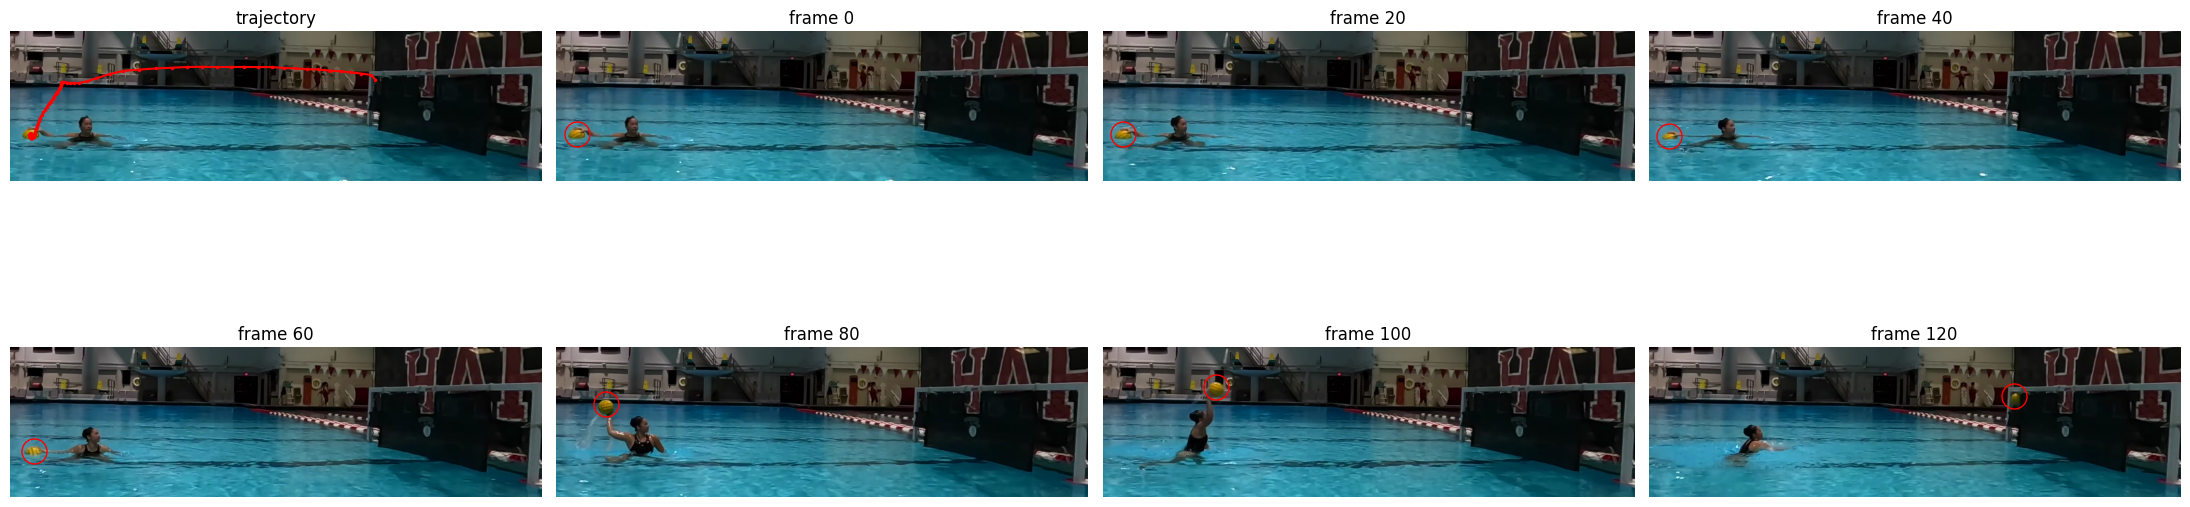

In [26]:
import pandas as pd

# Pick one candidate per frame: nearest to constant-velocity prediction, within a gate; stop after too many misses.
MAX_JUMP, MAX_MISS = 60, 5
track = [None] * len(frames)
start = next((i for i, c in enumerate(cands) if c), None)
assert start is not None, "No blob of the target colour in any frame: check the mask in Step 2"
track[start] = max(cands[start], key=lambda c: c[2])[:2]
prev, vel, miss = np.array(track[start]), np.zeros(2), 0

for i in range(start + 1, len(frames)):
    pred = prev + vel
    best = min(cands[i], key=lambda c: np.hypot(c[0] - pred[0], c[1] - pred[1]), default=None)
    if best is not None and np.hypot(best[0] - pred[0], best[1] - pred[1]) <= MAX_JUMP:
        cur = np.array(best[:2])
        vel = 0.5 * vel + 0.5 * (cur - prev)
        track[i], prev, miss = tuple(cur), cur, 0
    else:
        prev, miss = pred, miss + 1
        if miss > MAX_MISS:
            break

df = pd.DataFrame({"frame": range(len(frames)),
                   "x": [t[0] if t else np.nan for t in track],
                   "y": [t[1] if t else np.nan for t in track]})
print("tracked frames:", df.x.notna().sum(), "| range:", df.dropna().frame.min(), "-", df.dropna().frame.max())

# Overlay check: trajectory on one frame + a few frames with the detection
fig, axes = plt.subplots(2, 4, figsize=(22, 8))
ax = axes[0, 0]
ax.imshow(cv2.cvtColor(frames[start], cv2.COLOR_BGR2RGB)); ax.plot(df.x, df.y, "r.-", ms=3); ax.set_title("trajectory"); ax.axis("off")
shown = df.dropna().frame.iloc[np.linspace(0, df.x.notna().sum() - 1, 7).astype(int)]
for ax, i in zip(axes.ravel()[1:], shown):
    ax.imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB))
    ax.plot(df.x[i], df.y[i], "o", mfc="none", mec="red", ms=18); ax.set_title(f"frame {i}"); ax.axis("off")
plt.tight_layout(); plt.show()

## Step 7: Check the height over time
Plots the blob's vertical position per frame (up = higher). For the water polo ball this shows when it leaves the water and when tracking ends, which sets the airborne start rule in the next step.

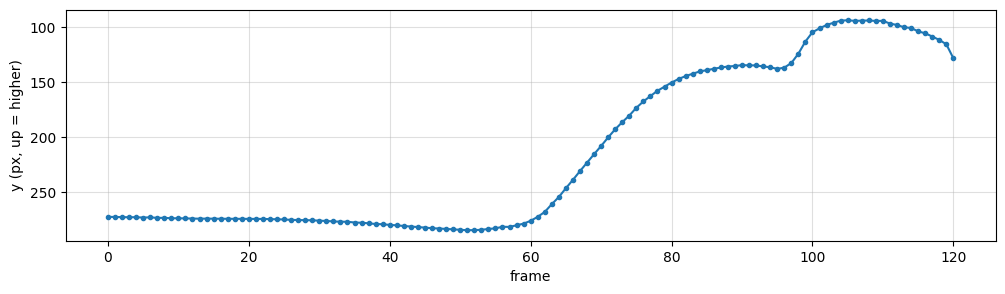

[276.0, 255.0, 223.0, 193.0, 168.0, 151.0, 141.0, 136.0, 135.0, 137.0, 105.0, 94.0, 94.0, 98.0, 106.0, 129.0, nan]


In [27]:
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(df.frame, df.y, ".-"); ax.invert_yaxis(); ax.set_xlabel("frame"); ax.set_ylabel("y (px, up = higher)"); ax.grid(alpha=.4)
plt.show()
print(df.y.iloc[60:125:4].round(0).tolist())

## Step 8: Keep the relevant part and save the track
With `AIRBORNE_ONLY = True` (thrown-ball videos) the frames where the ball rests on the water are dropped: the track starts at the first frame where the ball is more than 15 px above its starting height. Set it to `False` to keep the whole track. Saves `frame, x, y, x_orig, y_orig, t_s` to `<video>_<LABEL>_track.csv`, where `x_orig`/`y_orig` are coordinates in the original untrimmed frame (trim offset `CROP_OFFSET`; use `(0, 0)` for an untrimmed video). Also plots the kept trajectory.

Airborne frames 64-120 (57 points)
Saved: 01-F-01-TL-Back-2_trimmed_ball_track.csv


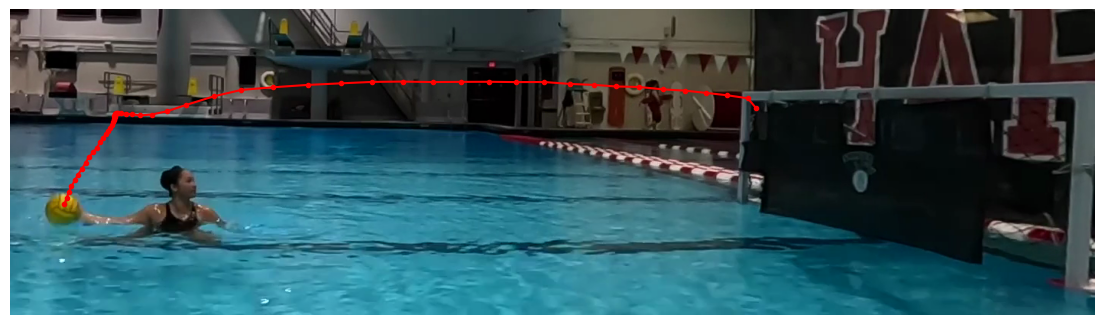

In [28]:
CROP_OFFSET = (500, 400)  # top_left used when trimming; adds back original-frame coordinates. (0, 0) if untrimmed
AIRBORNE_ONLY = True      # water polo: keep only the part after the ball leaves the water. False = whole track

if AIRBORNE_ONLY:  # from the first frame the ball rises clearly above its resting height on the water
    rest_y = df.y.dropna().iloc[:20].median()
    air_start = int(df.index[df.y < rest_y - 15][0])
else:
    air_start = int(df.x.first_valid_index())
air = df.iloc[air_start:].dropna().copy()
air["x_orig"], air["y_orig"] = air.x + CROP_OFFSET[0], air.y + CROP_OFFSET[1]
air["t_s"] = air.frame / fps

CSV = VIDEO.with_name(f"{VIDEO.stem}_{LABEL}_track.csv")
air.to_csv(CSV, index=False)

print(f"Kept frames {air.frame.min()}-{air.frame.max()} ({len(air)} points)")
print("Saved:", CSV.name)

fig, ax = plt.subplots(figsize=(14, 4))
ax.imshow(cv2.cvtColor(frames[air_start], cv2.COLOR_BGR2RGB)); ax.plot(air.x, air.y, "r.-"); ax.axis("off")
plt.show()

## Step 9: Render a video with the tracked blob and trail
Draws a circle on the blob in each kept frame, a fading trail of its last 30 positions, and the current `(x, y)` readout. The video is saved next to the input as `<video>_<LABEL>_tracked.mp4` and re-encoded to H.264 with ffmpeg (if available) so it plays in most players.

In [29]:
import subprocess, shutil

TRAIL = 30
OUT = VIDEO.with_name(f"{VIDEO.stem}_{LABEL}_tracked.mp4")
RAW = OUT.with_name("_tmp_" + OUT.name)
pos = {int(r.frame): (int(round(r.x)), int(round(r.y))) for r in air.itertuples()}

writer = cv2.VideoWriter(str(RAW), cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
history = []
for i, f in enumerate(frames):
    f = f.copy()
    if i in pos:
        history.append(pos[i])
        trail = history[-TRAIL:]
        for k in range(1, len(trail)):
            a = k / len(trail)  # older segments are thinner
            cv2.line(f, trail[k - 1], trail[k], (0, 0, 255), max(1, int(3 * a)), cv2.LINE_AA)
        cv2.circle(f, pos[i], 14, (0, 0, 255), 2, cv2.LINE_AA)
        cv2.putText(f, f"({pos[i][0] + CROP_OFFSET[0]}, {pos[i][1] + CROP_OFFSET[1]})", (pos[i][0] + 18, pos[i][1] - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2, cv2.LINE_AA)
    writer.write(f)
writer.release()

if shutil.which("ffmpeg"):
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(RAW), "-c:v", "libx264", "-pix_fmt", "yuv420p", str(OUT)], check=True)
    RAW.unlink()
else:
    RAW.rename(OUT)

print(f'Tracked video saved as "{OUT.name}" in {OUT.parent}')

Tracked video saved as "01-F-01-TL-Back-2_trimmed_ball_tracked.mp4" in /Users/souvikmandal/Documents/S06_Teaching_Mentoring_Talks/LS100/2026_Sem2/data/raw/water-polo_maya


## Step 10: Ball diameter in pixels and metric scale
*For a round object of known size; skip for other objects.* Measures the ball's apparent diameter in each kept frame from a looser colour mask around the tracked position (the learned range widened by `LOOSE_EXTRA`), using the ellipse's minor axis (perpendicular to motion blur). The median over frames gives `px_per_m = diameter_px / BALL_DIAMETER_M`. The ball is in its own plane of motion, so this scale applies at the ball's depth.

count    57.0
mean     35.3
std       5.4
min      14.4
25%      34.0
50%      35.6
75%      36.8
max      56.8

Median diameter 35.6 px -> 169.6 px/m (5.9 mm/px)


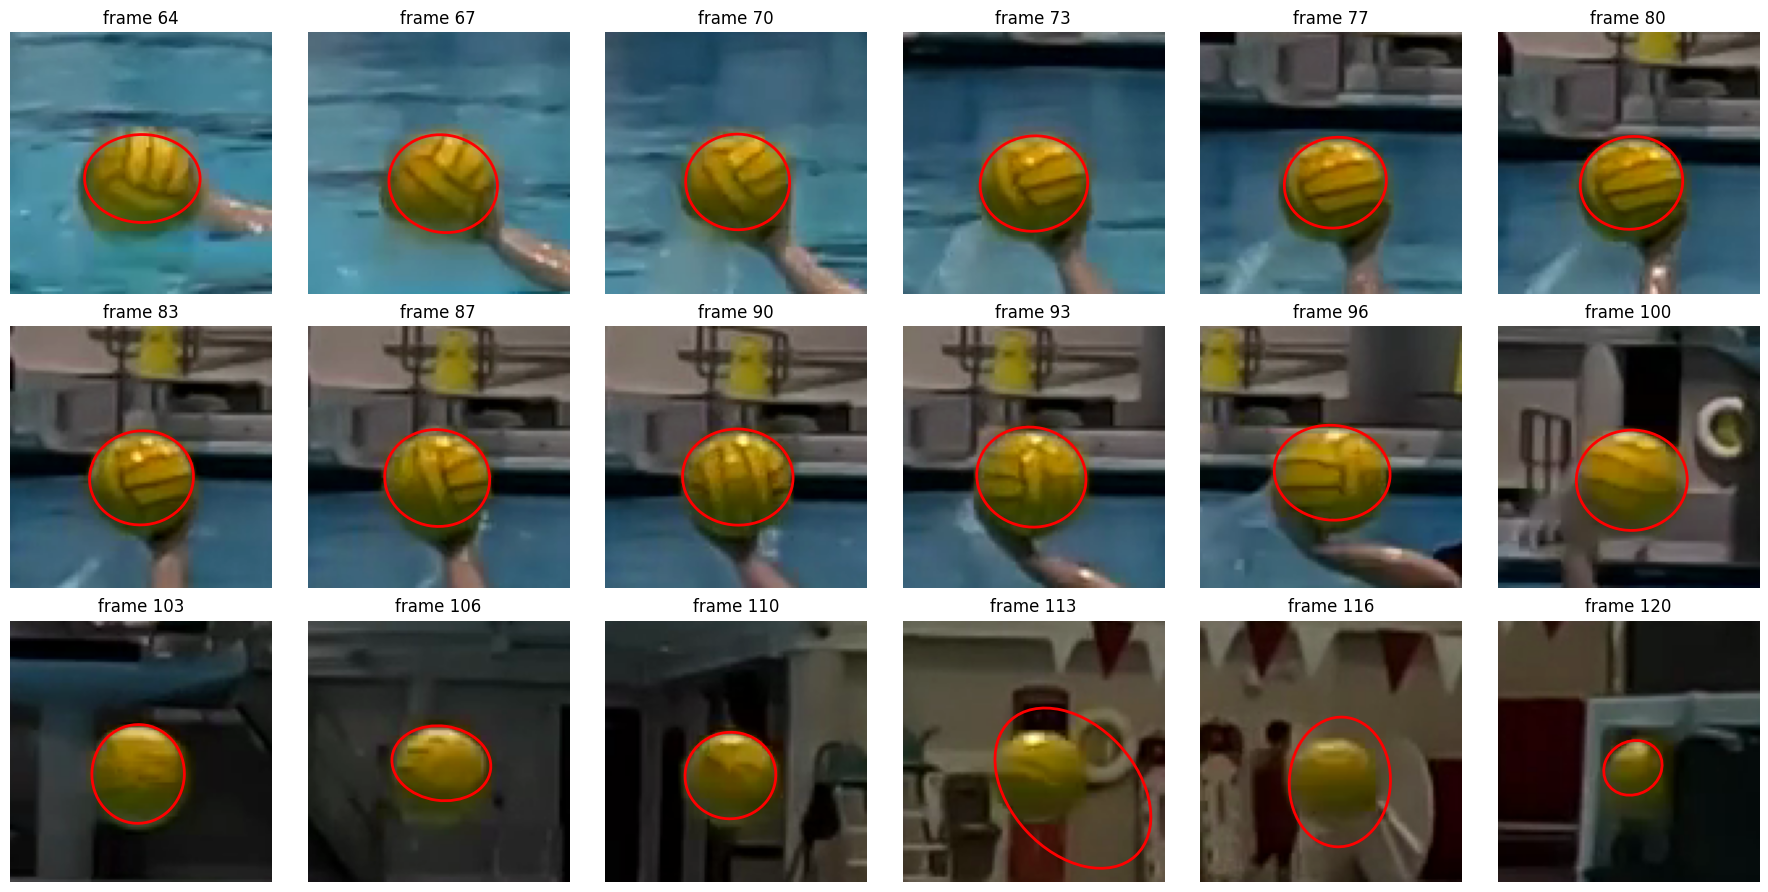

In [ ]:
BALL_DIAMETER_M = 0.21 #in meters
G = 9.81

# Slightly looser colour match than the detector, to include the ball's dark, blurred edge
LOOSE_EXTRA = (2, 5, 10)   # extra (hue, saturation, value) tolerance on top of the learned range

def ball_ellipse(i, x, y, half=45):
    """Ellipse ((cx, cy), (a, b), angle) of the ball blob near (x, y), in frame coordinates, or None."""
    x0, y0 = int(max(x - half, 0)), int(max(y - half, 0))
    patch = frames[i][y0:int(y + half), x0:int(x + half)]
    m = color_mask(patch, LOOSE_EXTRA).astype(np.uint8) * 255
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cnts = [c for c in cnts if len(c) >= 5 and cv2.contourArea(c) > 100
            and cv2.pointPolygonTest(c, (float(x - x0), float(y - y0)), True) > -12]
    if not cnts:
        return None
    (cx, cy), (a, b), ang = cv2.fitEllipse(max(cnts, key=cv2.contourArea))
    return (cx + x0, cy + y0), (a, b), ang

ells = {int(r.frame): ball_ellipse(int(r.frame), r.x, r.y) for r in air.itertuples()}
air["d_px"] = [min(ells[f][1]) if ells[f] else np.nan for f in air.frame]
print(air.d_px.describe().round(1).to_string())

d_px = air.d_px.median()
PX_PER_M = d_px / BALL_DIAMETER_M
print(f"\nMedian diameter {d_px:.1f} px -> {PX_PER_M:.1f} px/m ({1000 / PX_PER_M:.1f} mm/px)")

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for ax, i in zip(axes.ravel(), np.linspace(air.frame.min(), air.frame.max(), 18).astype(int)):
    r = air[air.frame == i].iloc[0]
    x0, y0 = int(max(r.x - 50, 0)), int(max(r.y - 50, 0))
    ax.imshow(cv2.cvtColor(frames[i][y0:int(r.y + 50), x0:int(r.x + 50)], cv2.COLOR_BGR2RGB))
    if ells[i]:
        (cx, cy), (a, b), ang = ells[i]
        ax.add_patch(__import__("matplotlib").patches.Ellipse((cx - x0, cy - y0), a, b, angle=ang, fill=False, ec="red", lw=2))
    ax.set_title(f"frame {i}"); ax.axis("off")
plt.tight_layout(); plt.show()

## Step 11: Ball speed in m/s
*For a thrown ball; skip for other objects.* Uses the ellipse centre as the ball position (frames with an implausible diameter fall back to the colour-blob centroid), converts to metres, and finds the release frame as the first frame where the ball moves faster than `RELEASE_PX_PER_FRAME`. During free flight, the horizontal motion is a straight line and the vertical motion a parabola, so $x(t)=x_0+v_xt$ and $y(t)=y_0+v_yt-\tfrac12 g_{fit}t^2$ (y up) are fitted to the flight frames. Air drag is ignored. `g_fit` should be close to 9.81 m/s² if the scale and track are good. Speeds are in the image plane only; motion toward or away from the camera is not captured. Set `RELEASE_FRAME`/`END_FRAME` manually to override the automatic choice.

Flight frames 96-118 (23 points, 0.37 s)
Release speed: 12.9 m/s (46 km/h)  vx=12.7, vy=2.2 m/s, angle=10 deg
Mean speed (path length / time): 12.3 m/s
Fitted g: 10.4 m/s^2 (expected 9.81)
Fit residual (RMS): 28 mm in y, 89 mm in x


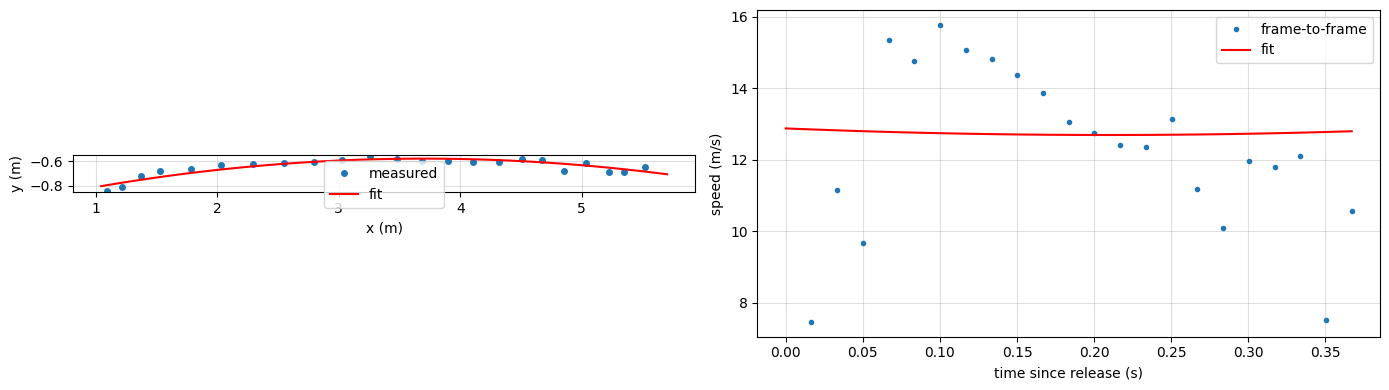

In [31]:
RELEASE_PX_PER_FRAME = 15   # px/frame; release = first frame faster than this
RELEASE_FRAME, END_FRAME = None, None  # set to override the automatic choice

# Best position estimate: ellipse centre when its size is plausible, else the colour-blob centroid
ok_d = (air.d_px > 0.8 * d_px) & (air.d_px < 1.2 * d_px)
air["xc"] = [ells[f][0][0] if ok else x for f, ok, x in zip(air.frame, ok_d, air.x)]
air["yc"] = [ells[f][0][1] if ok else y for f, ok, y in zip(air.frame, ok_d, air.y)]

# Metres, y pointing up
air["X"] = air.xc / PX_PER_M
air["Y"] = -air.yc / PX_PER_M
step = np.hypot(air.xc.diff(), air.yc.diff())

rel = RELEASE_FRAME if RELEASE_FRAME is not None else int(air.frame[step > RELEASE_PX_PER_FRAME].iloc[0])
end = END_FRAME if END_FRAME is not None else int(air.frame[ok_d].iloc[-1])
fl = air[(air.frame >= rel) & (air.frame <= end)]
t = (fl.frame - rel) / fps

px_, py_ = np.polyfit(t, fl.X, 1), np.polyfit(t, fl.Y, 2)
vx0, vy0, g_fit = px_[0], py_[1], -2 * py_[0]
v0 = np.hypot(vx0, vy0)

# Frame-to-frame speed (noisy) and fitted speed
v_raw = np.hypot(fl.X.diff(), fl.Y.diff()) * fps
tt = np.linspace(0, t.max(), 100)
v_fit = np.hypot(vx0, vy0 - g_fit * tt)

print(f"Flight frames {rel}-{end} ({len(fl)} points, {t.max():.2f} s)")
print(f"Release speed: {v0:.1f} m/s ({v0 * 3.6:.0f} km/h)  vx={vx0:.1f}, vy={vy0:.1f} m/s, angle={np.degrees(np.arctan2(vy0, vx0)):.0f} deg")
print(f"Mean speed (path length / time): {np.hypot(fl.X.diff(), fl.Y.diff()).sum() / t.max():.1f} m/s")
print(f"Fitted g: {g_fit:.1f} m/s^2 (expected 9.81)")
print(f"Fit residual (RMS): {np.sqrt(np.mean((np.polyval(py_, t) - fl.Y) ** 2)) * 1000:.0f} mm in y, "
      f"{np.sqrt(np.mean((np.polyval(px_, t) - fl.X) ** 2)) * 1000:.0f} mm in x")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(fl.X, fl.Y, "o", ms=4, label="measured")
axes[0].plot(np.polyval(px_, tt), np.polyval(py_, tt), "r-", label="fit")
axes[0].set_xlabel("x (m)"); axes[0].set_ylabel("y (m)"); axes[0].set_aspect("equal"); axes[0].legend(); axes[0].grid(alpha=.4)
axes[1].plot(t, v_raw, ".", label="frame-to-frame"); axes[1].plot(tt, v_fit, "r-", label="fit")
axes[1].set_xlabel("time since release (s)"); axes[1].set_ylabel("speed (m/s)"); axes[1].legend(); axes[1].grid(alpha=.4)
plt.tight_layout(); plt.show()